# Trabalho Prático: PPO (Proximal Policy Optimization) no Overcooked
# Aprendizado por Reforço 2025/1

#### Thaís Ferreira da Silva - 2021092571

**Última atualização:** Novembro 2025

Este notebook implementa um agente **PPO (Proximal Policy Optimization)** usando **CleanRL** para o ambiente Overcooked customizado.

**Objetivo:** Treinar um agente único para coletar ingredientes, processá-los e entregar receitas no `simple_map`.

**Por que CleanRL PPO?**
- ✅ **Simples e educacional** - Código limpo e fácil de entender
- ✅ **PPO é mais estável** - Melhor que DQN para ambientes complexos
- ✅ **Python 3.13 compatível** - Não depende de bibliotecas antigas
- ✅ **[Tutorial oficial PettingZoo](https://pettingzoo.farama.org/tutorials/cleanrl/)** - Implementação de referência

**Diferenças do ambiente Lunar Lander:**
- Observações: Grid 3D (altura × largura × 8 canais) ao invés de vetor 1D
- Policy: CNN (Convolutional Neural Network) ao invés de MLP
- Ambiente: Multi-agente PettingZoo (usando 1 agente)
- Algoritmo: PPO (policy gradient) ao invés de DQN (value-based)


## Instalação de Dependências

### **PROBLEMA RESOLVIDO! PyTorch CUDA instalado com sucesso**

**Status da sua instalação:**
- **PyTorch 2.7.1+cu118** (CUDA) instalado na venv
- **NVIDIA GeForce MX350** detectada e funcionando
- **CUDA disponível:** True

### **Comandos de Instalação Completos**

```bash
# 1. Ativar ambiente virtual
.\venv\Scripts\Activate.ps1

# 2. Instalar PyTorch CUDA
pip install torch --index-url https://download.pytorch.org/whl/cu118

# 3. Instalar outras dependências
pip install numpy matplotlib tqdm gymnasium pettingzoo pygame

# 4. Instalar o ambiente Overcooked
pip install -e .
```

### 📋 **O que cada biblioteca faz:**

| **Biblioteca** | **Função** | **Versão** |
|-------------------|---------------|----------------|
| `torch` | Deep learning (PPO, CNN) | **2.7.1+cu118** ✅ |
| `numpy` | Matemática e arrays | 1.21+ |
| `matplotlib` | Gráficos e visualização | 3.5+ |
| `tqdm` | Barras de progresso | Latest |
| `gymnasium` | Interface RL padrão | 0.29+ |
| `pettingzoo` | Multi-agent framework | 1.24+ |
| `pygame` | Renderização visual | 2.5+ |

## 1. Imports e Dependências


In [12]:
# Bibliotecas padrão
import os
import time
import random
from typing import Dict, Any, Optional, Tuple
from collections import deque

# Bibliotecas de terceiros
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# PyTorch para deep learning
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.distributions import Categorical

# DirectML para AMD GPUs (opcional)
try:
    import torch_directml
    DIRECTML_AVAILABLE = True
except ImportError:
    DIRECTML_AVAILABLE = False

# Gymnasium para interface RL
import gymnasium as gym
from gymnasium import spaces

# Nosso ambiente Overcooked (PettingZoo)
from overcooked_marl_env import OvercookedMARL

print("✅ Bibliotecas importadas com sucesso!")
print(f"PyTorch version: {torch.__version__}")

# Função para detectar device corretamente
def get_best_device():
    """
    Detecta automaticamente o melhor device disponível.
    
    Prioridade:
    1. CUDA (NVIDIA GPU)
    2. DirectML (AMD GPU)
    3. CPU
    
    Returns:
        tuple: (device, device_name)
    """
    if torch.cuda.is_available():
        device = torch.device("cuda")
        gpu_name = torch.cuda.get_device_name(0)
        print(f"NVIDIA GPU detectada: {gpu_name}")
        print("   -> Usando CUDA (recomendado)")
        return device, f"CUDA ({gpu_name})"
    
    if "cuda" not in torch.__version__ and torch.__version__.endswith("+cpu"):
        print("PyTorch CPU detectado!")
        print("   -> Sua NVIDIA GeForce MX350 pode usar CUDA")
        print("   -> Reinstale PyTorch CUDA para melhor performance:")
        print("   -> pip install torch --index-url https://download.pytorch.org/whl/cu118")
        print("   -> Por enquanto, usando CPU...")
        device = torch.device("cpu")
        return device, "CPU (PyTorch CPU version)"
    
    if DIRECTML_AVAILABLE:
        print("DirectML disponível")
        print("   -> Detectado como AMD GPU")
        print("   -> Usando DirectML")
        device = torch_directml.device()
        return device, "DirectML (AMD GPU)"
    
    # Fallback: CPU
    device = torch.device("cpu")
    print("💻 Usando CPU")
    print("   -> GPU não disponível ou não compatível")
    return device, "CPU"

# Função de teste corrigida
def test_device_compatibility(device):
    """
    Testa se o device suporta as operações necessárias para PPO.
    
    Args:
        device: Device PyTorch para testar
        
    Returns:
        bool: True se compatível, False caso contrário
    """
    try:
        print("\nTestando compatibilidade do device...")
        
        # Teste 1: Criação de tensors
        x = torch.randn(4, 5, 7, 8).to(device)  # Formato correto: (batch, height, width, channels)
        print("  Criação de tensors: OK")
        
        # Teste 2: Permutação para CNN (channels first)
        x_cnn = x.permute(0, 3, 1, 2)  # (batch, channels, height, width)
        print("  Permutação de dimensões: OK")
        
        # Teste 3: Operações CNN com dimensões corretas
        conv = nn.Conv2d(8, 16, 3, padding=1).to(device)  # 8 channels de entrada
        y = conv(x_cnn)
        print("  Operações CNN: OK")
        
        # Teste 4: Linear layers
        linear = nn.Linear(16 * 5 * 7, 64).to(device)  # Dimensões corretas
        z = linear(y.reshape(4, -1))
        print("  Camadas lineares: OK")
        
        # Teste 5: Backward pass (crítico para DirectML)
        loss = z.sum()
        loss.backward()
        print("  Backward pass: OK")
        
        print("Device totalmente compatível!")
        return True
        
    except Exception as e:
        print(f"Erro de compatibilidade: {e}")
        print("   -> Usando CPU para estabilidade")
        return False

# Detecta device automaticamente
device, device_name = get_best_device()
print(f"\nDevice selecionado: {device_name}")

# Testa compatibilidade apenas uma vez
is_compatible = test_device_compatibility(device)

# Se não for compatível, volta para CPU (sem loop)
if not is_compatible and device.type != "cpu":
    print("\nGPU não totalmente compatível - usando CPU")
    device = torch.device("cpu")
    device_name = "CPU (fallback)"

print(f"\nDevice final: {device_name}")
print(f"Torch device: {device}")


✅ Bibliotecas importadas com sucesso!
PyTorch version: 2.7.1+cu118
NVIDIA GPU detectada: NVIDIA GeForce MX350
   -> Usando CUDA (recomendado)

Device selecionado: CUDA (NVIDIA GeForce MX350)

Testando compatibilidade do device...
  Criação de tensors: OK
  Permutação de dimensões: OK
  Operações CNN: OK
  Camadas lineares: OK
  Backward pass: OK
Device totalmente compatível!

Device final: CUDA (NVIDIA GeForce MX350)
Torch device: cuda


## 2. Wrapper PettingZoo → Gymnasium

CleanRL trabalha com Gymnasium, então precisamos converter o ambiente PettingZoo:


In [13]:
class PettingZooToGymWrapper(gym.Env):
    """
    Converte ambiente PettingZoo com 1 agente para interface Gymnasium.
    
    CleanRL espera interface Gymnasium padrão (single-agent).
    """
    
    def __init__(self, pettingzoo_env):
        super().__init__()
        self.env = pettingzoo_env
        
        # Verifica se há apenas 1 agente
        if len(self.env.possible_agents) != 1:
            raise ValueError(f"Wrapper funciona apenas com 1 agente. Encontrados: {len(self.env.possible_agents)}")
        
        self.agent_id = self.env.possible_agents[0]
        
        # Define espaços
        self.action_space = self.env.action_spaces[self.agent_id]
        self.observation_space = self.env.observation_spaces[self.agent_id]
        
    def reset(self, seed=None, options=None):
        observations, infos = self.env.reset(seed=seed, options=options)
        return observations[self.agent_id], infos[self.agent_id]
    
    def step(self, action):
        actions = {self.agent_id: action}
        observations, rewards, terminations, truncations, infos = self.env.step(actions)
        
        obs = observations[self.agent_id]
        reward = rewards[self.agent_id]
        terminated = terminations[self.agent_id]
        truncated = truncations[self.agent_id]
        info = infos[self.agent_id]
        
        return obs, reward, terminated, truncated, info
    
    def render(self):
        return self.env.render()
    
    def close(self):
        self.env.close()

print("Wrapper criado!")


Wrapper criado!


## 3. Actor-Critic Network (PPO)

PPO usa uma rede Actor-Critic com CNN para processar observações espaciais:


In [14]:
class ActorCritic(nn.Module):
    """
    Rede Actor-Critic para PPO com CNN para observações espaciais.
    
    - Actor: Gera distribuição de probabilidades sobre ações
    - Critic: Estima valor do estado (V(s))
    """
    
    def __init__(self, observation_space, action_space):
        super().__init__()
        
        h, w, c = observation_space.shape
        n_actions = action_space.n
        
        # Feature extractor (CNN) compartilhado
        self.cnn = nn.Sequential(
            nn.Conv2d(c, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.Flatten(),
        )
        
        # Calcula tamanho da saída da CNN
        with torch.no_grad():
            sample = torch.zeros(1, c, h, w)
            n_flatten = self.cnn(sample).shape[1]
        
        # Camadas compartilhadas
        self.shared = nn.Sequential(
            nn.Linear(n_flatten, 128),
            nn.ReLU(),
        )
        
        # Actor head (policy)
        self.actor = nn.Linear(128, n_actions)
        
        # Critic head (value function)
        self.critic = nn.Linear(128, 1)
    
    def forward(self, x):
        # x: (batch, height, width, channels) -> (batch, channels, height, width)
        x = x.permute(0, 3, 1, 2)
        
        # Features
        features = self.shared(self.cnn(x))
        
        # Actor: logits das ações
        logits = self.actor(features)
        
        # Critic: valor do estado
        value = self.critic(features)
        
        return logits, value
    
    def get_action_and_value(self, x, action=None):
        """
        Retorna ação, log_prob, entropia e valor.
        Usado durante coleta de dados.
        """
        logits, value = self.forward(x)
        probs = Categorical(logits=logits)
        
        if action is None:
            action = probs.sample()
        
        return action, probs.log_prob(action), probs.entropy(), value

print("Rede Actor-Critic criada!")


Rede Actor-Critic criada!


## 4. Inicialização do Ambiente e Configuração PPO


In [15]:
# CONFIGURAÇÕES CENTRALIZADAS - CONSTANTES DO PROJETO
# ====================================================

# AMBIENTE
ENVIRONMENT_CONFIG = {
    'map_path': "overcooked_marl_env/map/maps/simple_map.txt",
    'num_fixed_agents': 1,
    'render_mode': None,
    'verbose': False,
    'max_episode_steps': 300,
    'environment_type': 'Overcooked_MARL'
}

# ARQUITETURA DO MODELO
MODEL_CONFIG = {
    'network_type': 'CNN_ActorCritic',
    'cnn_channels': [32, 64, 64],
    'cnn_kernel_sizes': [3, 3, 3],
    'cnn_strides': [1, 1, 1],
    'cnn_paddings': [1, 1, 0],
    'shared_hidden_size': 128,
    'activation_function': 'ReLU'
}

# AVALIAÇÃO
EVALUATION_CONFIG = {
    'num_episodes': 20,
    'max_steps_per_episode': 300,
    'success_threshold': -50,  # Reward > -50 = sucesso
    'models_to_evaluate': 'ALL',  # Avaliar TODOS os modelos
    'visualize_best_n': 3  # Visualizar apenas top 3
}

# TREINAMENTO
TRAINING_CONFIG = {
    'algorithm': 'PPO',
    'framework': 'CleanRL',
    'save_frequency': 5,  # Salvar a cada 5 updates
}

# Cria o ambiente
base_env = OvercookedMARL(
    render_mode=ENVIRONMENT_CONFIG['render_mode'],
    map_path=ENVIRONMENT_CONFIG['map_path'],
    num_fixed_agents=ENVIRONMENT_CONFIG['num_fixed_agents'],
    verbose=ENVIRONMENT_CONFIG['verbose']
)
env = PettingZooToGymWrapper(base_env)

print(f"Ambiente criado!")
print(f"Observation space: {env.observation_space}")
print(f"Action space: {env.action_space}")

# Adiciona informações do ambiente aos configs
MODEL_CONFIG['observation_space_shape'] = env.observation_space.shape
MODEL_CONFIG['action_space_size'] = env.action_space.n

# Configuração PPO (CleanRL style)
config = {
    # ========== TREINAMENTO ==========
    'total_timesteps': 1000,      # Total de steps para treinar
                                   # Teste: 5k | Treino normal: 50k | Treino longo: 100k+
    
    'learning_rate': 3e-4,         # Taxa de aprendizado
                                   # Conservador: 1e-4 | Normal: 3e-4 | Agressivo: 1e-3
    
    'num_steps': 256,              # Steps coletados por update (rollout buffer)
                                   # AUMENTADO: 128→256 para mais dados por update
                                   #  Mais steps = mais memória, mas melhor aprendizado
    
    'num_minibatches': 4,          # Divisões do batch (256÷4 = 64 samples/batch)
                                   # Balanceado: 4 | Mais fino: 8
    
    'update_epochs': 500,          # Vezes que treina com mesmos dados
                                   # AUMENTADO: 4→10 para extrair mais aprendizado
                                   # Cuidado: muito alto pode causar overfitting
    
    # ========== PPO ESPECÍFICO ==========
    'gamma': 0.99,                 # Desconto de recompensas futuras
                                   # Tarefas longas: 0.99 | Tarefas curtas: 0.95
    
    'gae_lambda': 0.95,            # Balance bias-variance (GAE)
                                   # Padrão: 0.95 funciona bem na maioria dos casos
    
    'clip_coef': 0.2,              # Limite de mudança da policy (estabilidade)
                                   # Conservador: 0.1 | Normal: 0.2 | Agressivo: 0.3
    
    'ent_coef': 0.1,               # Coeficiente de entropia (exploração)
                                   # AUMENTADO: 0.05→0.1 para MAIS exploração
                                   # Começa alto, pode diminuir depois (annealing)
    
    'vf_coef': 0.5,                # Peso da value function no loss
                                   # Padrão: 0.5 | Se value ruim: aumentar para 1.0
    
    'max_grad_norm': 0.5,          # Gradient clipping (evita explosão)
                                   # Normal: 0.5 | Se instável: diminuir para 0.3
    
    # ========== OUTROS ==========
    'seed': 42,                    # Seed para reprodutibilidade
}

print(f"\nConfiguração PPO:")
for k, v in config.items():
    print(f"  {k}: {v}")

print(f"\nConfigurações centralizadas carregadas:")
print(f"  Ambiente: {ENVIRONMENT_CONFIG['map_path']}")
print(f"  Arquitetura: {MODEL_CONFIG['network_type']}")
print(f"  Avaliação: {EVALUATION_CONFIG['models_to_evaluate']} modelos")

[ENV] Loading map from: overcooked_marl_env/map/maps/simple_map.txt
[ENV] Map loaded successfully:
  - Size: (7, 7)
  - Agents: ['agent_0']
  - Dispensers: 2
  - Recipes: ['SIMPLE_SALAD', 'GARDEN_SALAD', 'SIMPLE_SALAD']
Ambiente criado!
Observation space: Box(0, 255, (7, 7, 8), uint8)
Action space: Discrete(5)

Configuração PPO:
  total_timesteps: 1000
  learning_rate: 0.0003
  num_steps: 256
  num_minibatches: 4
  update_epochs: 500
  gamma: 0.99
  gae_lambda: 0.95
  clip_coef: 0.2
  ent_coef: 0.1
  vf_coef: 0.5
  max_grad_norm: 0.5
  seed: 42

Configurações centralizadas carregadas:
  Ambiente: overcooked_marl_env/map/maps/simple_map.txt
  Arquitetura: CNN_ActorCritic
  Avaliação: ALL modelos


## 5. Treinamento PPO (CleanRL style)

PPO coleta rollouts, calcula advantages e otimiza a policy:


In [16]:
# Seed para reprodutibilidade
random.seed(config['seed'])
np.random.seed(config['seed'])
torch.manual_seed(config['seed'])

# Device já foi configurado automaticamente na célula anterior
print(f"Usando device: {device_name}")
print(f"   PyTorch device: {device}")

# Configurações específicas do device
if device.type == "cuda":
    # CUDA: Configurações otimizadas
    torch.backends.cudnn.benchmark = True
    print("  CUDA otimizations: enabled")
    
elif device.type == "dml":  # DirectML
    # DirectML: Configurações conservadoras
    print("  DirectML: configured")
    
else:  # CPU
    # CPU: Configurações padrão
    torch.set_num_threads(4)  # Limita threads para não sobrecarregar
    print("  CPU threads: 4")

# Cria a rede e otimizador
agent = ActorCritic(env.observation_space, env.action_space).to(device)
optimizer = optim.Adam(agent.parameters(), lr=config['learning_rate'], eps=1e-5)

# Informações do modelo
num_params = sum(p.numel() for p in agent.parameters())
trainable_params = sum(p.numel() for p in agent.parameters() if p.requires_grad)

Usando device: CUDA (NVIDIA GeForce MX350)
   PyTorch device: cuda
  CUDA otimizations: enabled


In [17]:
# Loop de treinamento PPO
print("\n" + "="*60)
print("INICIANDO TREINAMENTO PPO (TESTE RÁPIDO)")
print("="*60 + "\n")

start_time = time.time()

# Sistema de salvamento dos top 10 modelos
import heapq
from pathlib import Path

# Cria diretório para modelos
models_dir = Path("models")
models_dir.mkdir(exist_ok=True)
top_models_dir = models_dir / "top_10"
top_models_dir.mkdir(exist_ok=True)

# Lista para manter os 10 melhores modelos (min-heap)
top_models = []  # [(reward, update, model_path), ...]
max_models_to_keep = 10

def save_top_model(reward, update, agent, config, episode_rewards, episode_lengths):
    """Salva modelo se estiver entre os top 10 - VERSÃO EXPANDIDA"""
    
    # Informações completas do modelo
    model_info = {
        # === TREINAMENTO ===
        'update': update,
        'reward': reward,
        'total_episodes': len(episode_rewards),
        'training_time': time.time() - start_time,
        'episode_rewards': episode_rewards.copy(),
        'episode_lengths': episode_lengths.copy(),
        
        # === CONFIGURAÇÕES EXPANDIDAS ===
        'ppo_config': config.copy(),
        'environment_config': ENVIRONMENT_CONFIG.copy(),
        'model_config': MODEL_CONFIG.copy(),
        'evaluation_config': EVALUATION_CONFIG.copy(),
        'training_config': TRAINING_CONFIG.copy(),
        
        # === SISTEMA ===
        'device_used': device_name,
        'pytorch_version': torch.__version__,
        'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
        
        # === ESTATÍSTICAS ===
        'final_mean_reward': np.mean(episode_rewards[-10:]) if len(episode_rewards) >= 10 else np.mean(episode_rewards),
        'reward_std': np.std(episode_rewards),
        'mean_episode_length': np.mean(episode_lengths),
        'total_timesteps': config['total_timesteps'],
        'timesteps_completed': update * config['num_steps'],
        
        # === METADADOS ===
        'model_version': '2.0',
        'notebook_source': 'TP_Overcooked.ipynb',
        'notes': f'Modelo treinado com {len(episode_rewards)} episódios'
    }
    
    model_path = top_models_dir / f"model_update_{update:04d}_reward_{reward:.2f}.pth"
    
    # Salva modelo e informações EXPANDIDAS
    torch.save({
        'model_state_dict': agent.state_dict(),
        'model_info': model_info,
        # Compatibilidade com versões antigas
        'config': config,
        'reward': reward,
        'update': update
    }, model_path)
    
    # Gerencia top 10
    if len(top_models) < max_models_to_keep:
        heapq.heappush(top_models, (reward, update, str(model_path)))
    elif reward > top_models[0][0]:  # Se é melhor que o pior dos top 10
        # Remove o pior modelo
        _, _, old_path = heapq.heappop(top_models)
        if Path(old_path).exists():
            Path(old_path).unlink()
        
        # Adiciona o novo modelo
        heapq.heappush(top_models, (reward, update, str(model_path)))
    else:
        # Remove o modelo atual (não está no top 10)
        if model_path.exists():
            model_path.unlink()
    
    print(f"Models: [{', '.join([f'{r:.1f}' for r, _, _ in sorted(top_models, reverse=True)])}]")

# Storage para rollouts
num_steps = config['num_steps']
obs_storage = torch.zeros((num_steps,) + env.observation_space.shape).to(device)
actions_storage = torch.zeros(num_steps).to(device)
logprobs_storage = torch.zeros(num_steps).to(device)
rewards_storage = torch.zeros(num_steps).to(device)
dones_storage = torch.zeros(num_steps).to(device)
values_storage = torch.zeros(num_steps).to(device)

# Métricas
episode_rewards = []
episode_lengths = []
current_episode_reward = 0
current_episode_length = 0

# Reseta o ambiente
obs, _ = env.reset()
obs = torch.Tensor(obs).to(device)

global_step = 0
num_updates = config['total_timesteps'] // num_steps

pbar = tqdm(range(1, num_updates + 1), desc="Training")

for update in pbar:
    # ====================
    # FASE 1: Coleta de Dados (Rollout)
    # ====================
    agent.eval()
    for step in range(num_steps):
        global_step += 1
        obs_storage[step] = obs
        
        # Seleciona ação
        with torch.no_grad():
            action, logprob, _, value = agent.get_action_and_value(obs.unsqueeze(0))
        
        actions_storage[step] = action
        logprobs_storage[step] = logprob
        values_storage[step] = value.flatten()
        
        # Step no ambiente (converte tensor para int escalar)
        next_obs, reward, terminated, truncated, info = env.step(int(action.item()))
        done = terminated or truncated
        
        rewards_storage[step] = torch.tensor(reward).to(device)
        dones_storage[step] = torch.tensor(done).to(device)
        
        obs = torch.Tensor(next_obs).to(device)
        
        # Métricas de episódio
        current_episode_reward += reward
        current_episode_length += 1
        
        if done:
            episode_rewards.append(current_episode_reward)
            episode_lengths.append(current_episode_length)
            current_episode_reward = 0
            current_episode_length = 0
            obs, _ = env.reset()
            obs = torch.Tensor(obs).to(device)
    
    # ====================
    # FASE 2: Calcula Advantages (GAE)
    # ====================
    with torch.no_grad():
        next_value = agent.get_action_and_value(obs.unsqueeze(0))[3]
        advantages = torch.zeros_like(rewards_storage).to(device)
        lastgaelam = 0
        
        for t in reversed(range(num_steps)):
            if t == num_steps - 1:
                nextnonterminal = 1.0 - dones_storage[t]
                nextvalues = next_value
            else:
                nextnonterminal = 1.0 - dones_storage[t]
                nextvalues = values_storage[t + 1]
            
            delta = rewards_storage[t] + config['gamma'] * nextvalues * nextnonterminal - values_storage[t]
            advantages[t] = lastgaelam = delta + config['gamma'] * config['gae_lambda'] * nextnonterminal * lastgaelam
        
        returns = advantages + values_storage
    
    # ====================
    # FASE 3: Otimização PPO
    # ====================
    agent.train()
    
    # Flatten batch
    b_obs = obs_storage.reshape((-1,) + env.observation_space.shape)
    b_logprobs = logprobs_storage.reshape(-1)
    b_actions = actions_storage.reshape(-1)
    b_advantages = advantages.reshape(-1)
    b_returns = returns.reshape(-1)
    b_values = values_storage.reshape(-1)
    
    # Normaliza advantages
    b_advantages = (b_advantages - b_advantages.mean()) / (b_advantages.std() + 1e-8)
    
    # Minibatch optimization
    batch_size = num_steps
    minibatch_size = batch_size // config['num_minibatches']
    
    for epoch in range(config['update_epochs']):
        b_inds = torch.randperm(batch_size)
        
        for start in range(0, batch_size, minibatch_size):
            end = start + minibatch_size
            mb_inds = b_inds[start:end]
            
            _, newlogprob, entropy, newvalue = agent.get_action_and_value(
                b_obs[mb_inds], b_actions.long()[mb_inds]
            )
            logratio = newlogprob - b_logprobs[mb_inds]
            ratio = logratio.exp()
            
            mb_advantages = b_advantages[mb_inds]
            
            # Policy loss (PPO clipping)
            pg_loss1 = -mb_advantages * ratio
            pg_loss2 = -mb_advantages * torch.clamp(ratio, 1 - config['clip_coef'], 1 + config['clip_coef'])
            pg_loss = torch.max(pg_loss1, pg_loss2).mean()
            
            # Value loss
            newvalue = newvalue.view(-1)
            v_loss = 0.5 * ((newvalue - b_returns[mb_inds]) ** 2).mean()
            
            # Entropy loss
            entropy_loss = entropy.mean()
            
            # Total loss
            loss = pg_loss - config['ent_coef'] * entropy_loss + v_loss * config['vf_coef']
            
            # Backward
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), config['max_grad_norm'])
            optimizer.step()
    
    # Update progress bar e salva top modelos
    if len(episode_rewards) > 0:
        recent_reward = np.mean(episode_rewards[-10:]) if len(episode_rewards) >= 10 else np.mean(episode_rewards)
        
        # Salva modelo se estiver entre os melhores (usa frequência das configs)
        if update % TRAINING_CONFIG['save_frequency'] == 0:
            save_top_model(recent_reward, update, agent, config, episode_rewards, episode_lengths)
        
        pbar.set_postfix({
            'reward': f"{recent_reward:.1f}",
            'episodes': len(episode_rewards),
            'top_models': len(top_models)
        })

training_time = time.time() - start_time

print("\n" + "="*60)
print("TREINAMENTO CONCLUÍDO")
print("="*60)
print(f"Tempo total: {training_time:.2f}s ({training_time/60:.2f} min)")
print(f"Total de episódios: {len(episode_rewards)}")
print(f"Total de steps: {global_step}")

# Salva o modelo final (sempre)
final_reward = np.mean(episode_rewards[-10:]) if len(episode_rewards) >= 10 else np.mean(episode_rewards)
save_top_model(final_reward, num_updates, agent, config, episode_rewards, episode_lengths)

# Salva também o modelo mais recente com informações completas
final_model_path = models_dir / "latest_model.pth"
final_model_info = {
    'update': num_updates,
    'reward': final_reward,
    'total_episodes': len(episode_rewards),
    'training_time': training_time,
    'episode_rewards': episode_rewards,
    'episode_lengths': episode_lengths,
    # === INFORMAÇÕES EXPANDIDAS TAMBÉM NO MODELO FINAL ===
    'ppo_config': config.copy(),
    'environment_config': ENVIRONMENT_CONFIG.copy(),
    'model_config': MODEL_CONFIG.copy(),
    'evaluation_config': EVALUATION_CONFIG.copy(),
    'training_config': TRAINING_CONFIG.copy(),
    'device_used': device_name,
    'pytorch_version': torch.__version__,
    'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
}

torch.save({
    'model_state_dict': agent.state_dict(),
    'model_info': final_model_info
}, final_model_path)

print(f"\nModelos salvos com configurações completas:")
print(f"   Top 10 modelos: {top_models_dir}")
print(f"   Último modelo: {final_model_path}")
print(f"   Total de modelos top 10: {len(top_models)}")
print(f"   Configurações salvas: Ambiente, PPO, Modelo, Avaliação, Sistema")

# Mostra ranking dos top modelos
if top_models:
	print(f"\nRANKING DOS TOP {len(top_models)} MODELOS:")
    
	for i, (reward, update, path) in enumerate(sorted(top_models, reverse=True), 1):
		print(f"   {i:2d}. Update {update:4d} - Reward: {reward:6.2f} - {Path(path).name}")


INICIANDO TREINAMENTO PPO (TESTE RÁPIDO)



Training: 100%|██████████| 3/3 [00:55<00:00, 18.53s/it, reward=72.0, episodes=1, top_models=0]


TREINAMENTO CONCLUÍDO
Tempo total: 55.60s (0.93 min)
Total de episódios: 1
Total de steps: 768
Models: [72.0]

Modelos salvos com configurações completas:
   Top 10 modelos: models\top_10
   Último modelo: models\latest_model.pth
   Total de modelos top 10: 1
   Configurações salvas: Ambiente, PPO, Modelo, Avaliação, Sistema

RANKING DOS TOP 1 MODELOS:
    1. Update    3 - Reward:  72.00 - model_update_0003_reward_72.00.pth


In [18]:
# SISTEMA DE AVALIAÇÃO IMPLEMENTADO!

print(f"Métricas coletadas!")
print(f"Total de episódios: {len(episode_rewards)}")

print(f"\nNOVO SISTEMA IMPLEMENTADO:")
print(f"   Top 10 modelos salvos automaticamente em: models/top_10/")
print(f"   Último modelo salvo em: models/latest_model.pth")
print(f"   Total de modelos no ranking: {len(top_models) if 'top_models' in locals() else 'Execute o treinamento'}")

Métricas coletadas!
Total de episódios: 1

NOVO SISTEMA IMPLEMENTADO:
   Top 10 modelos salvos automaticamente em: models/top_10/
   Último modelo salvo em: models/latest_model.pth
   Total de modelos no ranking: 1


## 6. Sistema de Avaliação Avançado

In [19]:
def moving_average(data, window_size):
    """Calcula a média móvel de uma lista."""
    if len(data) < window_size:
        return data
    
    smoothed = []
    for i in range(len(data) - window_size + 1):
        window = data[i:i + window_size]
        smoothed.append(sum(window) / window_size)
    return smoothed

# Estatísticas gerais
print("="*60)
print("ESTATÍSTICAS DO TREINAMENTO PPO")
print("="*60)

if len(episode_rewards) > 0:
    print(f"\nTotal de episódios: {len(episode_rewards)}")
    print(f"Total de timesteps: {global_step}")
    
    print(f"\nRecompensa média (todos episódios): {np.mean(episode_rewards):.2f}")
    print(f"Recompensa máxima: {np.max(episode_rewards):.2f}")
    print(f"Recompensa mínima: {np.min(episode_rewards):.2f}")
    
    if len(episode_rewards) >= 10:
        last_10 = episode_rewards[-10:]
        print(f"\nRecompensa média (últimos 10 episódios): {np.mean(last_10):.2f} ± {np.std(last_10):.2f}")
    
    print(f"\nDuração média dos episódios: {np.mean(episode_lengths):.1f} steps")
else:
    print("\nNenhuma métrica coletada ainda.")


ESTATÍSTICAS DO TREINAMENTO PPO

Total de episódios: 1
Total de timesteps: 768

Recompensa média (todos episódios): 72.00
Recompensa máxima: 72.00
Recompensa mínima: 72.00

Duração média dos episódios: 500.0 steps


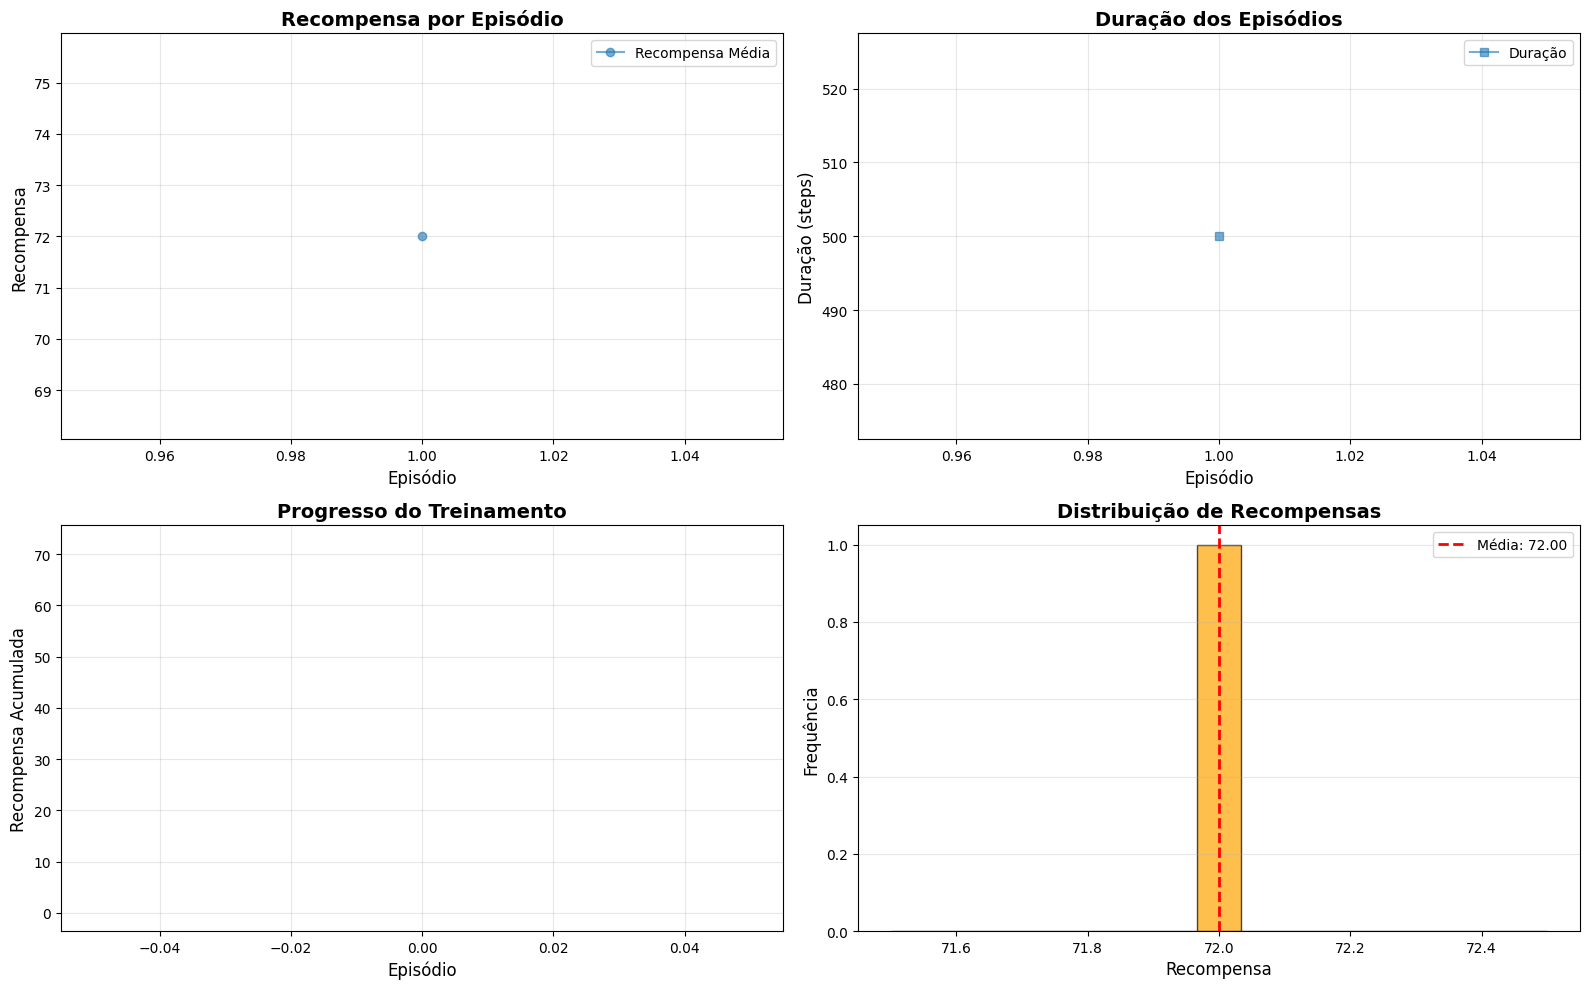


Gráficos salvos em: overcooked_ppo_training_results.png


In [20]:
# Visualização das métricas
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Recompensas por iteração
if len(episode_rewards) > 0:
    ax = axes[0, 0]
    iterations = range(1, len(episode_rewards) + 1)
    ax.plot(iterations, episode_rewards, alpha=0.6, marker='o', label='Recompensa Média')
    
    # Média móvel
    window = min(10, len(episode_rewards) // 3)
    if window > 1:
        smoothed = moving_average(episode_rewards, window)
        ax.plot(range(window, len(episode_rewards) + 1), smoothed, 
                linewidth=3, label=f'Média Móvel (janela={window})', color='red')
    
    ax.set_xlabel('Episódio', fontsize=12)
    ax.set_ylabel('Recompensa', fontsize=12)
    ax.set_title('Recompensa por Episódio', fontsize=14, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3)
else:
    axes[0, 0].text(0.5, 0.5, 'Sem dados de recompensa', ha='center', va='center')
    axes[0, 0].set_title('Recompensa por Episódio')

# 2. Duração dos episódios
if len(episode_lengths) > 0:
    ax = axes[0, 1]
    iterations = range(1, len(episode_lengths) + 1)
    ax.plot(iterations, episode_lengths, alpha=0.6, marker='s', label='Duração')
    
    # Média móvel
    window = min(10, len(episode_lengths) // 3)
    if window > 1:
        smoothed = moving_average(episode_lengths, window)
        ax.plot(range(window, len(episode_lengths) + 1), smoothed,
                linewidth=3, label=f'Média Móvel (janela={window})', color='green')
    
    ax.set_xlabel('Episódio', fontsize=12)
    ax.set_ylabel('Duração (steps)', fontsize=12)
    ax.set_title('Duração dos Episódios', fontsize=14, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3)
else:
    axes[0, 1].text(0.5, 0.5, 'Sem dados de duração', ha='center', va='center')
    axes[0, 1].set_title('Duração dos Episódios')

# 3. Progresso acumulado
if len(episode_rewards) > 0:
    ax = axes[1, 0]
    cumulative = [sum(episode_rewards[:i+1]) for i in range(len(episode_rewards))]
    ax.plot(range(len(episode_rewards)), cumulative, linewidth=2, color='purple')
    ax.set_xlabel('Episódio', fontsize=12)
    ax.set_ylabel('Recompensa Acumulada', fontsize=12)
    ax.set_title('Progresso do Treinamento', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.fill_between(range(len(episode_rewards)), cumulative, alpha=0.3)
else:
    axes[1, 0].text(0.5, 0.5, 'Sem dados', ha='center', va='center')
    axes[1, 0].set_title('Progresso do Treinamento')

# 4. Distribuição de recompensas
if len(episode_rewards) > 0:
    ax = axes[1, 1]
    ax.hist(episode_rewards, bins=15, edgecolor='black', alpha=0.7, color='orange')
    ax.axvline(np.mean(episode_rewards), color='red', 
               linestyle='--', linewidth=2, label=f'Média: {np.mean(episode_rewards):.2f}')
    ax.set_xlabel('Recompensa', fontsize=12)
    ax.set_ylabel('Frequência', fontsize=12)
    ax.set_title('Distribuição de Recompensas', fontsize=14, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
else:
    axes[1, 1].text(0.5, 0.5, 'Sem dados de distribuição', ha='center', va='center')
    axes[1, 1].set_title('Distribuição de Recompensas')

plt.tight_layout()
plt.savefig('overcooked_ppo_training_results.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nGráficos salvos em: overcooked_ppo_training_results.png")


## 8. Visualização do Agente Treinado

Vamos executar alguns episódios e visualizar o comportamento do agente treinado:


In [21]:
def visualize_agent_ppo(agent, env, num_episodes=2, max_steps=200, device=None):
    """
    Executa episódios com o agente PPO treinado e captura frames.
    
    Args:
        agent: Modelo Actor-Critic treinado
        env: Ambiente Overcooked (wrapper Gymnasium)
        num_episodes: Número de episódios para visualizar
        max_steps: Máximo de steps por episódio
        device: Device do PyTorch (auto-detectado se None)
    """
    # Usa device global se não especificado
    if device is None:
        device = next(agent.parameters()).device
    
    # Cria ambiente com render_mode="rgb_array"
    viz_env = OvercookedMARL(
        render_mode="rgb_array",
        map_path="overcooked_marl_env/map/maps/simple_map.txt",
        num_fixed_agents=1,
        verbose=False
    )
    viz_env = PettingZooToGymWrapper(viz_env)
    
    all_episodes_frames = []
    all_episodes_info = []
    
    agent.eval()  # Modo de avaliação
    
    print(f"🎬 Executando {num_episodes} episódios de demonstração...")
    print(f"   Device: {device}")
    
    for episode in range(num_episodes):
        obs, info = viz_env.reset()
        episode_reward = 0
        episode_frames = []
        steps = 0
        
        # Captura frame inicial
        frame = viz_env.env.render()
        if frame is not None:
            episode_frames.append(frame)
        
        done = False
        while not done and steps < max_steps:
            # Seleciona ação usando o agente treinado (determinístico)
            with torch.no_grad():
                obs_tensor = torch.Tensor(obs).unsqueeze(0).to(device)
                action, _, _, _ = agent.get_action_and_value(obs_tensor)
                action = int(action.item())
            
            obs, reward, terminated, truncated, info = viz_env.step(action)
            done = terminated or truncated
            
            episode_reward += reward
            steps += 1
            
            # Captura frame
            frame = viz_env.env.render()
            if frame is not None:
                episode_frames.append(frame)
        
        all_episodes_frames.append(episode_frames)
        all_episodes_info.append({
            'episode': episode + 1,
            'reward': episode_reward,
            'steps': steps
        })
        
        print(f"   Episódio {episode + 1}: Recompensa = {episode_reward:.2f}, Steps = {steps}")
    
    viz_env.close()
    
    return all_episodes_frames, all_episodes_info

# Executa e captura frames (usa device automaticamente detectado)
print("Executando episódios de demonstração com o modelo treinado...")
all_frames, episodes_info = visualize_agent_ppo(agent, env, num_episodes=2, max_steps=200, device=device)

print(f"\nTotal de frames capturados: {sum(len(frames) for frames in all_frames)}")
print(f"   Device usado: {device_name}")

Executando episódios de demonstração com o modelo treinado...
[ENV] Loading map from: overcooked_marl_env/map/maps/simple_map.txt
[ENV] Map loaded successfully:
  - Size: (7, 7)
  - Agents: ['agent_0']
  - Dispensers: 2
  - Recipes: ['SIMPLE_SALAD', 'GARDEN_SALAD', 'SIMPLE_SALAD']
🎬 Executando 2 episódios de demonstração...
   Device: cuda
   Episódio 1: Recompensa = 24.00, Steps = 200
   Episódio 2: Recompensa = 34.00, Steps = 200

Total de frames capturados: 402
   Device usado: CUDA (NVIDIA GeForce MX350)


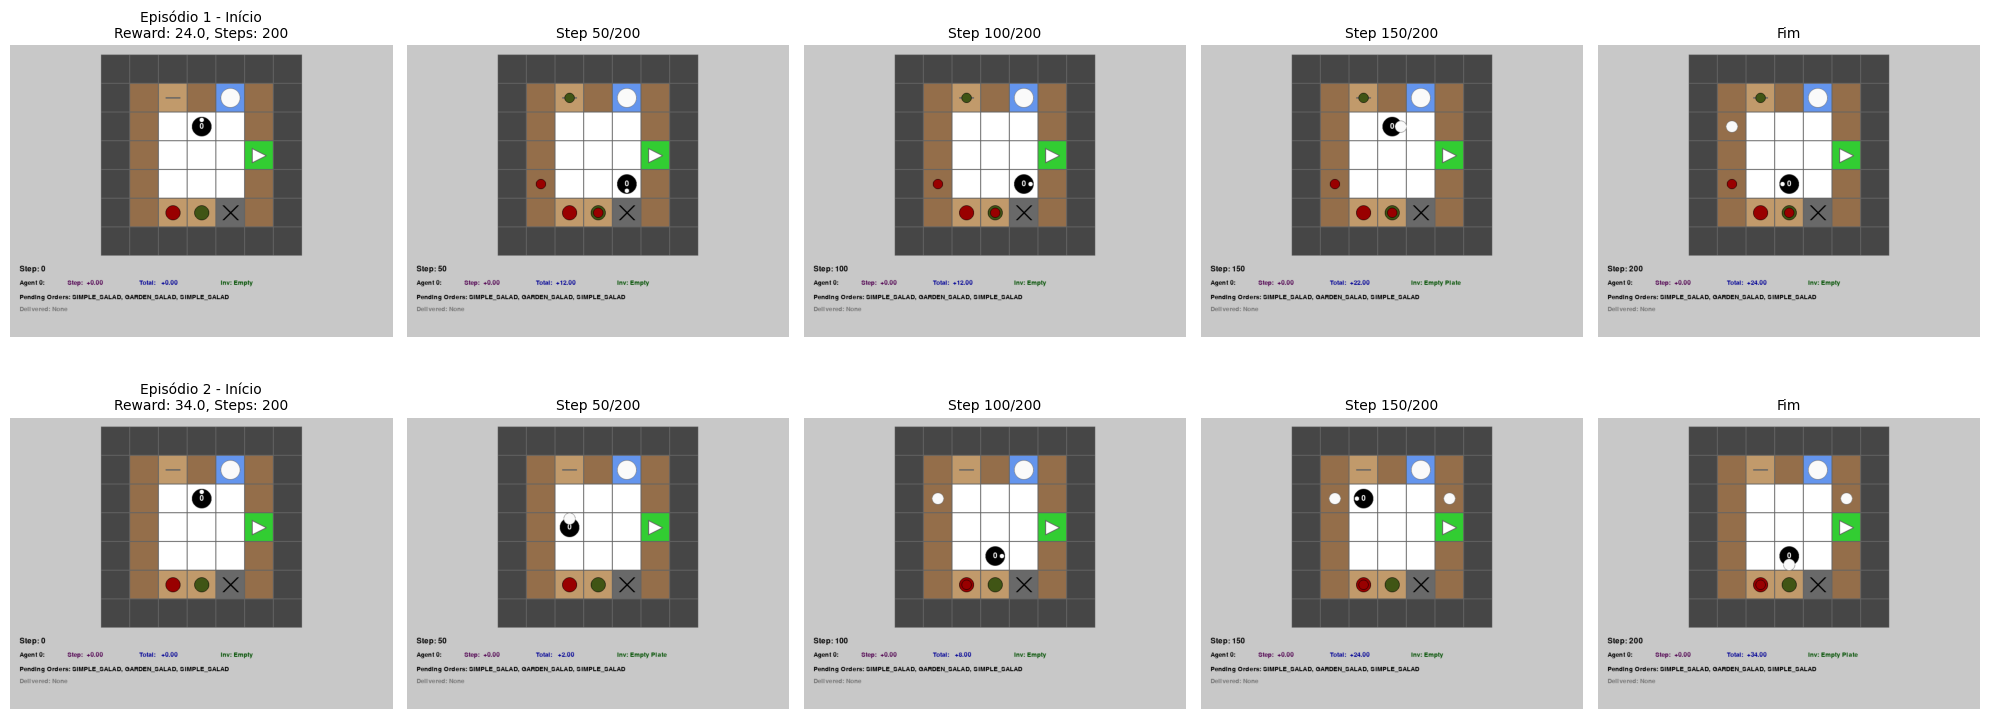


Visualização salva em: overcooked_agent_visualization.png


In [22]:
# Visualiza frames selecionados de cada episódio
num_episodes_viz = len(all_frames)
fig, axes = plt.subplots(num_episodes_viz, 5, figsize=(20, 4 * num_episodes_viz))

for episode_idx, (frames, info) in enumerate(zip(all_frames, episodes_info)):
    if len(frames) == 0:
        continue
    
    # Seleciona 5 frames igualmente espaçados ao longo do episódio
    indices = np.linspace(0, len(frames) - 1, 5, dtype=int)
    
    for col_idx, frame_idx in enumerate(indices):
        # Suporta 1 ou múltiplos episódios
        ax = axes[col_idx] if num_episodes_viz == 1 else axes[episode_idx, col_idx]
        ax.imshow(frames[frame_idx])
        ax.axis('off')
        
        if col_idx == 0:
            ax.set_title(f"Episódio {info['episode']} - Início\n"
                        f"Reward: {info['reward']:.1f}, Steps: {info['steps']}", 
                        fontsize=10)
        elif col_idx == len(indices) - 1:
            ax.set_title(f"Fim", fontsize=10)
        else:
            ax.set_title(f"Step {frame_idx}/{len(frames)-1}", fontsize=10)

plt.tight_layout()
plt.savefig('overcooked_agent_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nVisualização salva em: overcooked_agent_visualization.png")
